# Applied Machine Learning (P556) | Homework 1 Question 1
## Assignment Submisison

Student: Reed Turgeon

> Disclosures
>
> This assignment was completed with research assistance by Claude (Desktop & CLI) & Gemini (Browser)

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from utils.read_csv_to_df import read_csv_to_df
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis

TARGET = 'Life Ladder'

In [2]:
# import warnings
# warnings.filterwarnings('ignore')

# QA Summarize the Data

In [3]:
train_path = '/Q1_OLD_OLD/DATA/happiness_data_train.csv'
train_df = read_csv_to_df(path=train_path)

test_path = '/Q1_OLD_OLD/DATA/happiness_data_test.csv'
test_df = read_csv_to_df(path=test_path)

combined_df = pd.concat([train_df, test_df])

## QA.1 - How much Data is Present?

## QA.2 - What attributes / features are continuous?

## QA.3 - Which attributes are categorical?

# QB Statistical Values


## QB.1 - Statistical Values

### Callout 2: Perceptions of Corruption's "Outliers" Are a Real Group


### Callout 3: Missing Values Come in Clusters

## QB.3 - Attributes Requiring Special Treatment

| Attribute | Key trait | Special treatment |
|---|---|---|
| **All features** | Very different scales (years, log dollars, 0 to 1 shares, centered at 0) | Standardize, fit on the training set only |
| **Perceptions of corruption** | Most skewed (-1.54), most missing (86), 130 IQR outliers that are a real low corruption group, L shaped link to the target | Median impute; Yeo-Johnson; **keep** outliers; add a "Corruption < 0.5" flag or nonlinear term for linear models |
| **Social support** | Strong left skew (-1.14), bunched near 1.0, 42 low outliers | Yeo-Johnson; keep outliers |
| **Generosity** | Centered at 0 with negative values, right skew (0.83), missing whenever GDP is missing, weakest predictor (r = 0.19) | Yeo-Johnson (a log cannot handle negatives); impute; first candidate to drop |
| **Negative affect** | Right skew (0.70), 20 high outliers, weak predictor (r = -0.30) | Yeo-Johnson; candidate to drop |
| **Log GDP per capita** | Strongest predictor, already log scaled, overlaps with Life expectancy (r = 0.85) | Impute; Ridge / Lasso or keep one of the pair |
| **Healthy life expectancy** | Only feature in years, left skew (-0.72), 19 low but real values | Scale; Ridge / Lasso or keep one of the pair |
| **Freedom, Positive affect** | Mild skew, few outliers, little missing | Median impute and scale only |
| **Life Ladder (target)** | Nearly symmetric, no missing values, no outliers | None |
| **5 sparse rows** | Missing 6 of 8 features | Consider dropping from training |

# QC Analyze Relationships

> Please see "Appendix A | Data Exploration" for the full correlation table, scatter matrix and each feature's scatter plot against the target. Only the key relationships are called out here.

## QC.1 - Pearson Correlation Coefficients

Pearson's r measures how closely two attributes follow a **straight line** together, from -1 (perfect inverse line) through 0 (no linear link) to +1 (perfect line). Computed on the training set only. pandas drops missing values pair by pair, so every pair uses at least 1,415 rows.

Strength labels used below: **strong** |r| ≥ 0.7, **moderate** 0.4 to 0.7, **weak** < 0.4.

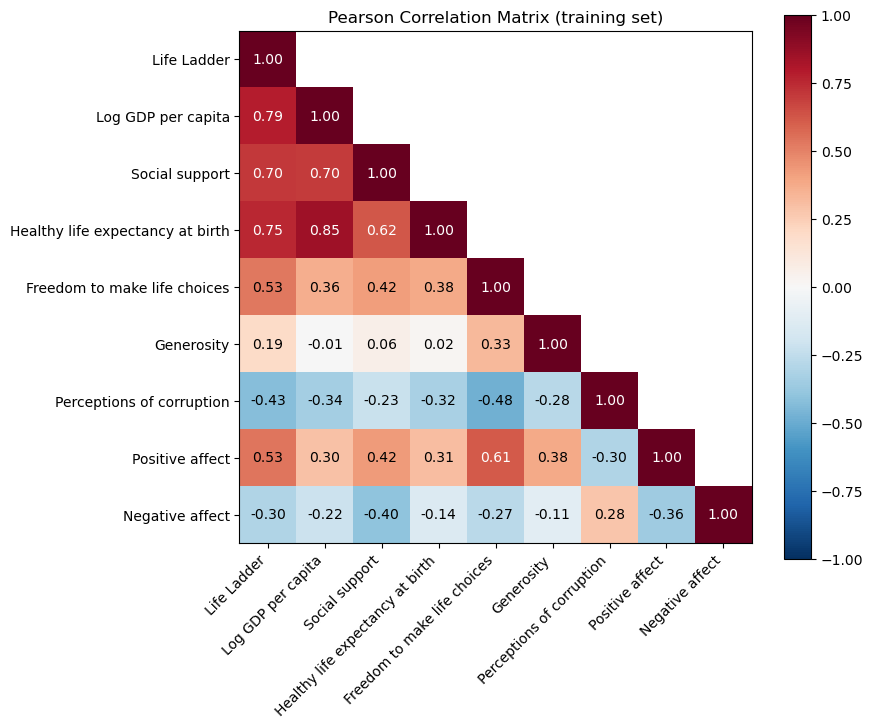

In [13]:
corr_matrix = train_df.corr(method='pearson')

# hide the upper triangle, since it mirrors the lower one
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
labels = corr_matrix.columns

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_matrix.mask(mask), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)

# white text on dark cells, black on light cells
for i in range(len(labels)):
	for j in range(i + 1):
		value = corr_matrix.iloc[i, j]
		ax.text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if abs(value) > 0.6 else 'black')

ax.set_title('Pearson Correlation Matrix (training set)')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

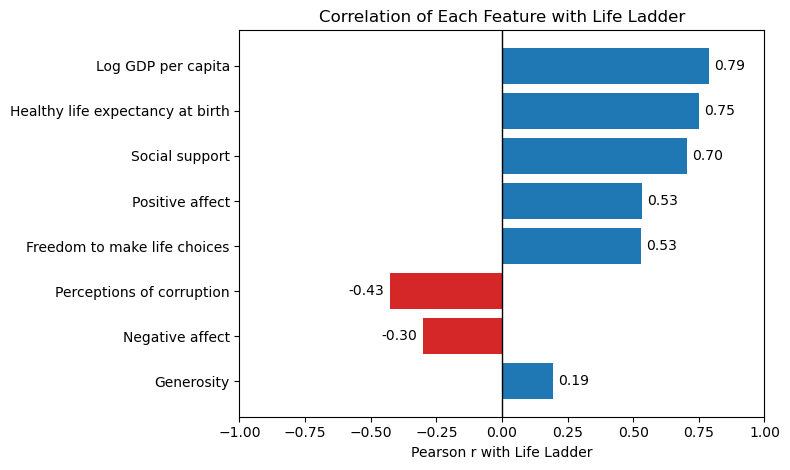

In [14]:
target_corr = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(target_corr.index, target_corr, color=['tab:blue' if r > 0 else 'tab:red' for r in target_corr])
for y, r in enumerate(target_corr):
	ax.text(r + (0.02 if r > 0 else -0.02), y, f'{r:.2f}', va='center', ha='left' if r > 0 else 'right')
ax.axvline(0, color='black', lw=1)
ax.set_xlim(-1, 1)
ax.set_xlabel(f'Pearson r with {TARGET}')
ax.set_title(f'Correlation of Each Feature with {TARGET}')
plt.tight_layout()
plt.show()

### Notes / Observations

**Attributes vs label (Life Ladder)**
- **Strong:** Log GDP (0.79), Healthy life expectancy (0.75), Social support (0.70).
- **Moderate:** Positive affect (0.53), Freedom (0.53), Perceptions of corruption (-0.43).
- **Weak:** Negative affect (-0.30), Generosity (0.19).
- Every sign matches intuition: wealth, health, support, freedom and joy rise with happiness; corruption and worry fall with it.
- GDP alone explains about 62% of the variation in happiness (r² = 0.79² ≈ 0.62), so even a one feature linear model would be a solid baseline.

**Attributes vs attributes**
- The strongest pairs are Log GDP and Life expectancy (0.85), Log GDP and Social support (0.70), and Social support and Life expectancy (0.62). These three are also the three strongest predictors (Callout 1).
- A second, looser group links Freedom, Positive affect and (inversely) Corruption, with r between 0.48 and 0.61 (Callout 2).
- Generosity and Negative affect are only weakly tied to every other attribute, with no |r| above 0.40 (Callout 4).
- No feature pair is close to ±1, so no feature is an exact copy of another.

## QC.2 - Key Relationships

### Callout 1: The "Wealth and Development" Cluster (GDP, Life Expectancy, Social Support)

The three strongest predictors are also strongly correlated with each other, so they partly carry the same signal. Two checks show how much:
- **Variance Inflation Factor (VIF):** how much of a feature can be predicted from all the others. It is the diagonal of the inverse correlation matrix. VIF = 1 means no overlap; above 5 is a common warning sign.
- **Correlation with GDP removed:** the correlation that is left between a feature and the target after subtracting out the straight line part each one shares with GDP (a partial correlation).

In [15]:
features = train_df.columns.drop(TARGET)
feature_corr = train_df[features].corr()

vif = pd.Series(np.diag(np.linalg.inv(feature_corr)), index=features, name='VIF')
vif.sort_values(ascending=False).round(2)

Log GDP per capita                  4.52
Healthy life expectancy at birth    3.82
Social support                      2.49
Freedom to make life choices        2.02
Positive affect                     1.91
Perceptions of corruption           1.51
Negative affect                     1.37
Generosity                          1.27
Name: VIF, dtype: float64

In [16]:
gdp = 'Log GDP per capita'
cluster_features = ['Healthy life expectancy at birth', 'Social support']
partial_df = train_df[[TARGET, gdp] + cluster_features].dropna()


def remove_gdp(column):
	"""Return what is left of a column after subtracting its best fit straight line on GDP."""
	slope, intercept = np.polyfit(partial_df[gdp], partial_df[column], 1)
	return partial_df[column] - (slope * partial_df[gdp] + intercept)


target_without_gdp = remove_gdp(TARGET)

pd.DataFrame({
	'r with target': [partial_df[f].corr(partial_df[TARGET]) for f in cluster_features],
	'r with target, GDP removed': [remove_gdp(f).corr(target_without_gdp) for f in cluster_features],
}, index=cluster_features).round(2)

,r with target,"r with target, GDP removed"
Healthy life expectancy at birth,0.75,0.25
Social support,0.71,0.35


#### Notes / Observations
- **VIF:** Log GDP (4.52) and Life expectancy (3.82) have the highest values, followed by Social support (2.49). Every other feature is at 2.02 or below. All are under 5, so the overlap is real but moderate, not severe.
- **GDP removed:** Life expectancy's link to happiness drops from 0.75 to 0.25, while Social support keeps more (0.71 to 0.35). Even though Life expectancy has the higher raw r, **Social support adds more information that GDP does not already carry.** (The 0.71 differs slightly from 0.70 because this check only uses rows with all four values.)
- **Implication for modeling:** in a linear model, the shared signal makes the GDP and Life expectancy coefficients unstable and hard to interpret. Ridge or Lasso handles this; if dropping a feature instead, Life expectancy is the one to drop, since it adds the least once GDP is in the model.

### Callout 2: The "Freedom and Mood" Cluster (Freedom, Positive Affect, Corruption)

No new chart needed: see the heatmap in QC.1.
- Freedom is tied to Positive affect (0.61) and, inversely, to Corruption (-0.48). Countries where people feel free to make life choices also tend to report more daily enjoyment and less corruption.
- This group is only loosely tied to wealth: Freedom (0.36), Positive affect (0.30) and Corruption (-0.34) all have weak correlations with GDP.
- **Implication for modeling:** these features carry a "quality of daily life" signal that the wealth cluster does not, so they are worth keeping alongside GDP. Their VIFs are low (2.02 or below), so keeping all three together is safe.

### Callout 3: Pearson Overstates Perceptions of Corruption

Pearson only measures **straight line** relationships and is sensitive to outliers. Spearman's correlation is computed the same way but on the **ranks** of the values, so it captures any steady up or down trend (curved or not) and gives outliers less pull. A large gap between the two points to a feature where Pearson's number is misleading.

In [17]:
method_compare = pd.DataFrame({
	'Pearson': corr_matrix[TARGET],
	'Spearman': train_df.corr(method='spearman')[TARGET],
}).drop(TARGET)
method_compare['Spearman - Pearson'] = method_compare['Spearman'] - method_compare['Pearson']

method_compare.sort_values('Spearman - Pearson', key=abs, ascending=False).round(3)

,Pearson,Spearman,Spearman - Pearson
Perceptions of corruption,-0.428,-0.319,0.108
Social support,0.704,0.747,0.044
Negative affect,-0.302,-0.260,0.042
Healthy life expectancy at birth,0.751,0.788,0.037
Generosity,0.195,0.170,-0.025
Log GDP per capita,0.787,0.799,0.013
Freedom to make life choices,0.530,0.538,0.008
Positive affect,0.535,0.536,0.001


#### Notes / Observations
- **Corruption has by far the largest gap:** Pearson -0.43 vs Spearman -0.32, a difference of 0.11, more than twice the next largest. Pearson is being pulled by the 174 low corruption rows that are much happier than everyone else (QB Callout 2). Within the other 1,299 rows (Corruption ≥ 0.5), Pearson r is only -0.18, so a single straight line overstates how much Corruption helps.
- **Negative affect** shows the same pattern on a smaller scale (Pearson -0.30 vs Spearman -0.26). Removing its 20 high IQR outliers drops Pearson to -0.27, close to Spearman, so a few very high worry countries make the straight line link look stronger than it is.
- **Social support (+0.04) and Life expectancy (+0.04)** go the other way: Spearman is higher, meaning the relationship is steady but slightly curved (ex: the upward bend for Social support noted in Appendix A), and a straight line fits a curve a little worse.
- The other four features differ by 0.03 or less, so Pearson describes them well.
- **Implication for modeling:** Corruption's r = -0.43 should not be read as a steady linear effect. Its signal is mostly "very low corruption vs everyone else", which is why QB recommends a Corruption < 0.5 flag or a nonlinear term.

### Callout 4: Generosity and Negative Affect Stand Apart

No new chart needed: see the heatmap in QC.1.
- **Generosity** is essentially unrelated to the wealth cluster: r = -0.01 with GDP, 0.02 with Life expectancy and 0.06 with Social support. Its closest links are Positive affect (0.38) and Freedom (0.33). The near zero GDP correlation is expected, since Generosity is calculated as what is left after removing GDP's effect on donations (QB Callout 3).
- **Negative affect** is most related to Social support (-0.40): countries with less support report more worry, anger and sadness.
- Both have the weakest links to happiness (0.19 and -0.30) and the lowest VIFs (1.27 and 1.37).
- **Implication for modeling:** these two add little predictive power, but what they add is not repeated by any other feature. They are the first candidates to drop in a simpler model, or to leave in and let Lasso decide.

## QC.3 - Relationship Summary

| Relationship | Pearson r | What it means |
|---|---|---|
| **Log GDP ↔ Life Ladder** | 0.79 | Strongest predictor; explains about 62% of the variation on its own |
| **Life expectancy ↔ Life Ladder** | 0.75 | Strong, but drops to 0.25 once GDP is removed: mostly repeats GDP |
| **Social support ↔ Life Ladder** | 0.70 | Strong, and keeps 0.35 once GDP is removed: adds real new information |
| **Positive affect, Freedom ↔ Life Ladder** | 0.53, 0.53 | Moderate; a "quality of daily life" signal separate from wealth |
| **Corruption ↔ Life Ladder** | -0.43 | Overstated by Pearson (Spearman -0.32); driven by the low corruption group, so not a steady linear effect |
| **Negative affect, Generosity ↔ Life Ladder** | -0.30, 0.19 | Weak; first candidates to drop |
| **Log GDP ↔ Life expectancy** | 0.85 | Strongest feature pair; VIFs of 4.5 and 3.8 mean moderate multicollinearity. Use Ridge / Lasso or drop Life expectancy |
| **Log GDP ↔ Social support** | 0.70 | Part of the same wealth cluster, but Social support still adds information beyond GDP |
| **Freedom ↔ Positive affect** | 0.61 | Core of the freedom and mood cluster; low VIFs, safe to keep together |
| **Generosity ↔ Log GDP** | -0.01 | No linear link, by construction of the Generosity measure |

# QD Train Linear Regression Model

> Please see "Appendix B | Linear Regression Model" for the full code. Only the key findings are called out here.

# QE Train Polynomial Regression Model

> Please see "Appendix C | Polynomial Regression Model" for the full code. Only the key findings are called out here.

# QF Make Predictions

> The final models were trained on the entire training set in "Appendix B | Linear Regression Model" (QD.7) and "Appendix C | Polynomial Regression Model" (QE.6), then saved to `Q1/MODELS/`. They are loaded here without retraining. The test set has not been used for any training, tuning or model choice up to this point.

## QF.1 - Choose the Model (Cross-Validation Only)

The model is chosen **before** the test set is touched, using only the 4-fold cross-validation RMSE from the appendices. Picking it by test RMSE instead would turn the test set into one more validation set, and the reported test RMSE would no longer be an honest estimate.

In [18]:
MODELS_DIR = '/Q1_OLD/MODELS'

saved_models = {
	'Linear (Appendix B)': joblib.load(f'{MODELS_DIR}/linear_regression_model.joblib'),
	'Polynomial (Appendix C)': joblib.load(f'{MODELS_DIR}/polynomial_regression_model.joblib'),
}

# lowest cross-validation RMSE wins; the test set plays no part in this choice
chosen_name = min(saved_models, key=lambda name: saved_models[name]['val RMSE'])
chosen_model = saved_models[chosen_name]['model']

pd.DataFrame({
	name: {
		'hyperparameters': saved['name'],
		'train RMSE': round(saved['train RMSE'], 4),
		'CV val RMSE': f"{saved['val RMSE']:.4f} ± {saved['val RMSE std']:.4f}",
		'chosen': 'yes' if name == chosen_name else '',
	}
	for name, saved in saved_models.items()
}).T

FileNotFoundError: [Errno 2] No such file or directory: '/Q1_OLD/MODELS/linear_regression_model.joblib'

## QF.2 - Predict the Test Set

`chosen_model` is the full pipeline (median impute, Yeo-Johnson, scale, polynomial expansion, rescale, SGD), so it takes the raw test features directly. Every imputation value, transform and scaling factor was learned from the training set only.

In [ ]:
test_X = test_df.drop(columns=TARGET)
test_y = test_df[TARGET]

test_predictions = chosen_model.predict(test_X)
test_rmse = np.sqrt(mean_squared_error(test_y, test_predictions))

print(f'Chosen model: {chosen_name} ({saved_models[chosen_name]["name"]})')
print(f'Test rows: {len(test_X)}')
print(f'Test RMSE: {test_rmse:.4f}')

## QF.3 - Performance Summary

The table puts the test RMSE next to what cross-validation expected. Two reference rows are added for context only (the choice above is already locked in):
- **Baseline:** always predict the training mean Life Ladder. Any useful model must beat this.
- **Linear (Appendix B):** the runner-up, scored on the same test rows so the gain from polynomial features can be checked on unseen data.

In [ ]:
def scores(y_true, y_pred):
	return {
		'test RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
		'test MAE': mean_absolute_error(y_true, y_pred),
		'test R2': r2_score(y_true, y_pred),
	}


baseline_predictions = np.full(len(test_y), train_df[TARGET].mean())
summary_rows = {'Baseline (training mean)': {'train RMSE': np.nan, 'CV val RMSE': np.nan, **scores(test_y, baseline_predictions)}}
for name, saved in saved_models.items():
	summary_rows[name + (' (chosen)' if name == chosen_name else '')] = {
		'train RMSE': saved['train RMSE'],
		'CV val RMSE': saved['val RMSE'],
		**scores(test_y, saved['model'].predict(test_X)),
	}

test_summary = pd.DataFrame(summary_rows).T
test_summary['test - CV'] = test_summary['test RMSE'] - test_summary['CV val RMSE']
test_summary.round(4)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
residuals = test_y - test_predictions
lims = [min(test_y.min(), test_predictions.min()) - 0.2, max(test_y.max(), test_predictions.max()) + 0.2]

axes[0].scatter(test_y, test_predictions, s=14, alpha=0.6)
axes[0].plot(lims, lims, color='black', lw=1, ls='--', label='perfect prediction')
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel(f'Actual {TARGET}')
axes[0].set_ylabel(f'Predicted {TARGET}')
axes[0].set_title(f'Predicted vs Actual (test RMSE = {test_rmse:.3f})')
axes[0].legend(loc='upper left')

axes[1].scatter(test_y, residuals, s=14, alpha=0.6)
axes[1].axhline(0, color='black', lw=1, ls='--')
axes[1].set_xlabel(f'Actual {TARGET}')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residuals vs Actual')

fig.suptitle(f'Test Set, {chosen_name}')
plt.tight_layout()
plt.show()

In [ ]:
happiness_band = pd.cut(test_y, bins=[0, 4, 5, 6, 7, 10], labels=['below 4', '4 to 5', '5 to 6', '6 to 7', 'above 7'])
residuals.groupby(happiness_band, observed=True).agg(
	rows='count',
	mean_residual='mean',
	RMSE=lambda r: np.sqrt((r ** 2).mean()),
).round(3)

#### Notes / Observations
- **Final answer: test RMSE = 0.498** for the chosen model (degree 3 polynomial, Elastic Net `alpha = 0.01`, `l1_ratio = 0.5`, `adaptive` learning rate with `eta0 = 0.001`, seed 42), on all 334 test rows. Test R² is 0.819 and MAE is 0.379 Life Ladder points.
- **Cross-validation predicted this almost exactly.** The CV estimate was 0.493 ± 0.033 and the test RMSE is only 0.005 higher, well inside one standard deviation. The linear model shows the same small gap (0.534 to 0.539). This confirms the appendices did not overfit their hyperparameter choices to the validation folds, and that the test set behaves like the training data.
- **Huge improvement over guessing.** Predicting the training mean for every row gives RMSE 1.170 (R² about 0), so the model removes 57% of that error.
- **The polynomial model beats the linear model on unseen data too:** 0.498 vs 0.539, 7.7% lower, matching the 7.8% gain measured fold by fold in QE.7. The choice made with cross-validation holds up on the test set.
- **Most predictions are close:** 70% land within 0.5 points of the true score and 94% within 1 point.
- **Errors pull toward the middle.** The least happy countries (below 4) are overpredicted by 0.65 points on average (RMSE 0.84), and the happiest (above 7) are underpredicted by 0.23. Rows in the middle of the range (5 to 7) are the most accurate (RMSE about 0.38). The model knows the broad picture but cannot fully explain extreme scores from these 8 features, a pattern the linear model shares (0.65 overprediction below 4).
- **The single largest miss shows the risk of cubic terms.** One country (actual 3.46) is predicted at 2.10, below anything a straight line would give: its low Positive affect and high Negative affect combine through the polynomial terms into an overly strong push down. The linear model predicts 3.70 for the same row. Without this one row the test RMSE would be 0.493.